In [34]:
# The project directory where the images, masks and annotations are stored needs to be updated
PROJECT_DIR = Path("./SAM-UNet/")
# This notebook expects the image, mask and manifest directories generated by the notebook SAM2-Hiera-Large-Teacher-Segmentation-Model.ipynb.

In [1]:
!pip install -q gdown
# Download pre-trained model of U-Net based on carvana dataset
!gdown "https://drive.google.com/uc?id=1WK-BsxPHHNNrnAgT6rga-nN1Ne5CTF64" \
    -O carvana_segmentation.pth.tar
# TODO: Check if randowm weight intialization works better

Downloading...
From (original): https://drive.google.com/uc?id=1WK-BsxPHHNNrnAgT6rga-nN1Ne5CTF64
From (redirected): https://drive.google.com/uc?id=1WK-BsxPHHNNrnAgT6rga-nN1Ne5CTF64&confirm=t&uuid=da560d0d-eaf4-46e0-9dfd-e172a1f9a979
To: /content/carvana_segmentation.pth.tar
100% 373M/373M [00:06<00:00, 60.9MB/s]


In [3]:
# Define all the libraries
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import torch.nn.functional as F
from models import UNet
import cv2

from pathlib import Path
import json
import random
import time
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import drive

In [4]:
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
GPU: True
Tesla T4


In [5]:
model = UNet(
    in_channels=3,
    out_channels=1
).to(device)

checkpoint = torch.load(
    "carvana_segmentation.pth.tar",
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["state_dict"])

<All keys matched successfully>

In [ ]:
drive.mount("/content/drive")

IMAGE_DIR = PROJECT_DIR / "images"
MASK_DIR = PROJECT_DIR / "masks"
MANIFEST_PATH = PROJECT_DIR / "annotations" / "manifest.json"

manifest = json.loads(MANIFEST_PATH.read_text())
records = manifest["annotations"]

print("Teacher:", manifest["annotator"])
print("Image-mask pairs:", len(records))

In [10]:
# # RGB images: resized to 256x256 and normalized to [0, 1].
# Binary masks: resized using nearest-neighbour interpolation.
SEED = 42
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IMAGE_SIZE = (256, 256)  # height, width



def load_pair(record):
    image_path = IMAGE_DIR / record["image"]
    # Get the file name from the old mask path and look it up in MASK_DIR
    mask_filename = Path(record["mask_path"]).name
    mask_path = MASK_DIR / mask_filename

    image = Image.open(image_path).convert("RGB").resize(
        (IMAGE_SIZE[1], IMAGE_SIZE[0]), Image.Resampling.BILINEAR
    )
    mask = Image.open(mask_path).convert("L").resize(
        (IMAGE_SIZE[1], IMAGE_SIZE[0]), Image.Resampling.NEAREST
    )

    x = np.asarray(image, dtype=np.float32) / 255.0
    y = (np.asarray(mask, dtype=np.uint8) > 127).astype(np.float32)
    return x, y[..., None]


loaded = [load_pair(record) for record in records]
images = np.stack([item[0] for item in loaded])
masks = np.stack([item[1] for item in loaded])

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Mean foreground fraction:", float(masks.mean()))

Images: (142, 256, 256, 3)
Masks: (142, 256, 256, 1)
Mean foreground fraction: 0.5817415714263916


In [11]:
np.random.seed(SEED)
indices = np.random.permutation(len(images))
n_total = len(indices)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)

train_idx = indices[:n_train]
val_idx = indices[n_train:n_train + n_val]
test_idx = indices[n_train + n_val:]

x_train, y_train = images[train_idx], masks[train_idx]
x_val, y_val = images[val_idx], masks[val_idx]
x_test, y_test = images[test_idx], masks[test_idx]

print(
    f"Train: {len(x_train)} | Validation: {len(x_val)} "
    f"| Test: {len(x_test)}"
)

if len(x_train) < 10:
    raise ValueError("Too few masks. Generate more annotations in Notebook 01.")

Train: 99 | Validation: 21 | Test: 22


In [12]:
def make_dataset(images, masks):
    images = torch.tensor(
        images, dtype=torch.float32
    ).permute(0, 3, 1, 2)

    masks = torch.tensor(
        masks, dtype=torch.float32
    ).permute(0, 3, 1, 2)

    return TensorDataset(images, masks)

train_loader = DataLoader(
    make_dataset(x_train, y_train), batch_size=8, shuffle=True
)
val_loader = DataLoader(
    make_dataset(x_val, y_val), batch_size=8
)
test_loader = DataLoader(
    make_dataset(x_test, y_test), batch_size=8
)

In [13]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [14]:
images, masks = next(iter(train_loader))

print("Image shape:", images.shape)
print("Mask shape:", masks.shape)

images = images.to(device)
masks = masks.to(device)

outputs = model(images)

print("Model output:", outputs.shape)

assert outputs.shape == masks.shape

Image shape: torch.Size([8, 3, 256, 256])
Mask shape: torch.Size([8, 1, 256, 256])
Model output: torch.Size([8, 1, 256, 256])


In [15]:
#BATCH_SIZE = 8
EPOCHS = 20
PATIENCE = 5

train_losses = []
val_losses = []

best_val_loss = float("inf")
patience_counter = 0

for epoch in range(EPOCHS):

    # Training
    model.train()
    running_loss = 0.0

    for batch_images, batch_masks in train_loader:

        batch_images = batch_images.to(device)
        batch_masks = batch_masks.to(device)

        optimizer.zero_grad()

        outputs = model(batch_images)
        loss = criterion(outputs, batch_masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_train_loss = running_loss / len(train_loader)

    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch_images, batch_masks in val_loader:

            batch_images = batch_images.to(device)
            batch_masks = batch_masks.to(device)

            outputs = model(batch_images)
            loss = criterion(outputs, batch_masks)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(val_loader)

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train: {epoch_train_loss:.4f} | "
        f"Validation: {epoch_val_loss:.4f}"
    )

    # Save best model
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        patience_counter = 0

        torch.save(
            model.state_dict(),
            "best_unet_leaf.pth"
        )
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping.")
        break

Epoch 1/20 | Train: 1.2807 | Validation: 0.9442
Epoch 2/20 | Train: 0.9169 | Validation: 0.7488
Epoch 3/20 | Train: 0.7565 | Validation: 0.6958
Epoch 4/20 | Train: 0.6777 | Validation: 0.6618
Epoch 5/20 | Train: 0.6572 | Validation: 0.6112
Epoch 6/20 | Train: 0.6521 | Validation: 0.6215
Epoch 7/20 | Train: 0.6447 | Validation: 0.5840
Epoch 8/20 | Train: 0.6378 | Validation: 0.5815
Epoch 9/20 | Train: 0.6355 | Validation: 0.5845
Epoch 10/20 | Train: 0.6177 | Validation: 0.5793
Epoch 11/20 | Train: 0.6043 | Validation: 0.5789
Epoch 12/20 | Train: 0.6223 | Validation: 0.5772
Epoch 13/20 | Train: 0.6160 | Validation: 0.6024
Epoch 14/20 | Train: 0.6182 | Validation: 0.5873
Epoch 15/20 | Train: 0.6136 | Validation: 0.5598
Epoch 16/20 | Train: 0.6147 | Validation: 0.5806
Epoch 17/20 | Train: 0.6179 | Validation: 0.5878
Epoch 18/20 | Train: 0.6115 | Validation: 0.5716
Epoch 19/20 | Train: 0.5998 | Validation: 0.6055
Epoch 20/20 | Train: 0.6005 | Validation: 0.5715
Early stopping.


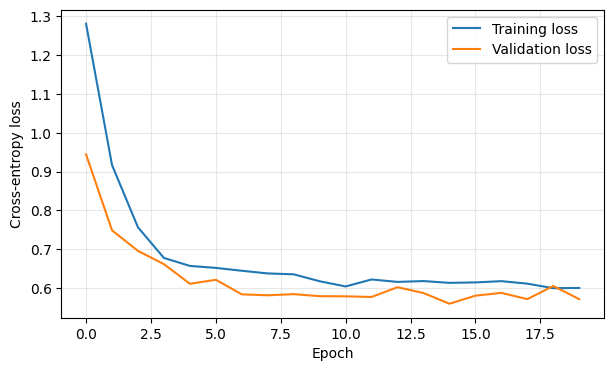

In [30]:
plt.figure(figsize=(7, 4))

plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [23]:
def predict_leaf_mask(model, image, device):

    original_size = image.size  # (width, height)

    resized = image.resize(
        (IMAGE_SIZE[1], IMAGE_SIZE[0]),
        Image.Resampling.BILINEAR
    )

    image_array = np.asarray(
        resized, dtype=np.float32
    ) / 255.0

    image_tensor = torch.from_numpy(
        image_array
    ).permute(2, 0, 1).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        logits = model(image_tensor)
        probability = torch.sigmoid(logits)

        mask = (probability > 0.5).float()

        mask = F.interpolate(
            mask,
            size=(original_size[1], original_size[0]),
            mode="nearest"
        )

    return mask.squeeze().cpu().numpy().astype(bool)

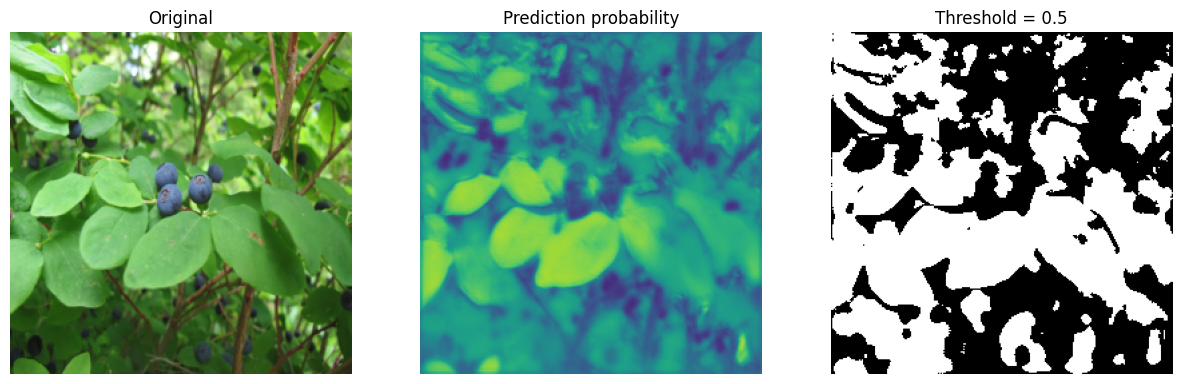

In [18]:
# Get a sample from the test set to visualize predictions
sample_idx = 0
sample_image_np = x_test[sample_idx]
# Add batch dimension, permute to (B, C, H, W) and transfer to device
image_tensor = torch.tensor(sample_image_np, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(image_tensor)
    probability = torch.sigmoid(logits).squeeze().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(sample_image_np)
axes[0].set_title("Original")

axes[1].imshow(probability, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Prediction probability")

axes[2].imshow(probability > 0.5, cmap="gray")
axes[2].set_title("Threshold = 0.5")

for ax in axes:
    ax.axis("off")

plt.show()

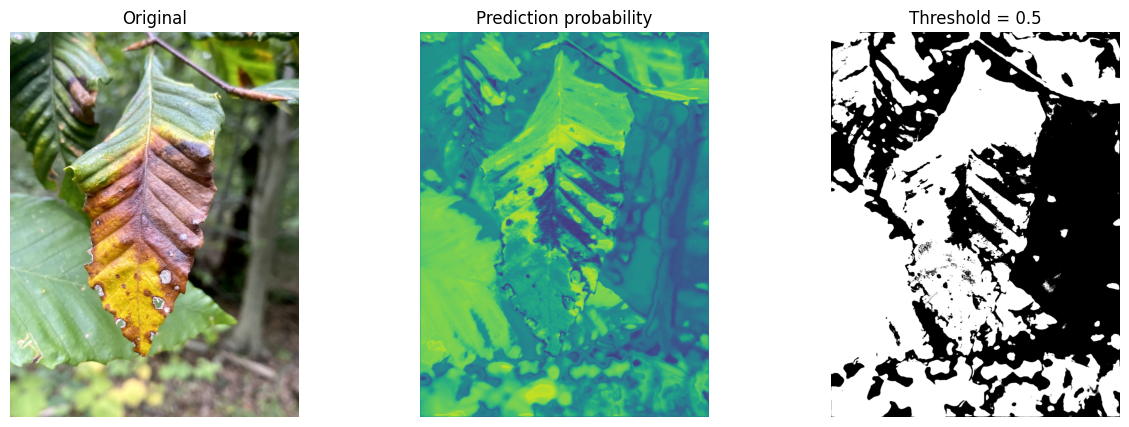

In [27]:
image = Image.open("/content/Beech_leaf.jpg").convert("RGB")

leaf_mask = predict_leaf_mask(model, image, device)

# Convert PIL Image to a normalized numpy array first, then to a torch tensor
image_np = np.asarray(image, dtype=np.float32) / 255.0
image_tensor = torch.tensor(image_np, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(image_tensor)
    probability = torch.sigmoid(logits).squeeze().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original")

axes[1].imshow(probability, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Prediction probability")

axes[2].imshow(probability > 0.5, cmap="gray")
axes[2].set_title("Threshold = 0.5")

for ax in axes:
    ax.axis("off")

plt.show()

In [28]:


def classify_leaf_tissue(image, leaf_mask):

    rgb = np.asarray(image, dtype=np.uint8)

    # OpenCV floating-point Lab conversion:
    # L*: 0-100, a* and b*: approximately -128 to 127
    rgb_float = rgb.astype(np.float32) / 255.0

    lab = cv2.cvtColor(
        rgb_float, cv2.COLOR_RGB2LAB
    )

    L = lab[:, :, 0]
    a = lab[:, :, 1]
    b = lab[:, :, 2]

    chroma = np.sqrt(a**2 + b**2)

    hue = (
        np.degrees(np.arctan2(b, a)) + 360
    ) % 360

    # Defined based on SME knowledge and is rule-based
    healthy = (
        leaf_mask & (hue >= 110)
    )

    chlorotic = (
        leaf_mask
        & (hue >= 70)
        & (hue <= 110)
        & (chroma >= 15)
    )

    necrotic = (
        leaf_mask
        & (
            ((hue >= 45) & (hue <= 85))
            | (L < 24)
            | (chroma < 10)
        )
    )

    # Resolve overlapping rules by giving necrotic priority.
    chlorotic &= ~necrotic
    healthy &= ~(necrotic | chlorotic)

    classified = healthy | chlorotic | necrotic

    total = classified.sum()

    if total == 0:
        return {
            "healthy": 0.0,
            "chlorotic": 0.0,
            "necrotic": 0.0
        }

    return {
        "healthy": 100 * healthy.sum() / total,
        "chlorotic": 100 * chlorotic.sum() / total,
        "necrotic": 100 * necrotic.sum() / total
    }

In [29]:
tissue_percentages = classify_leaf_tissue(
    image, leaf_mask
)

print(tissue_percentages)

{'healthy': np.float64(77.59760993786061), 'chlorotic': np.float64(11.467096848235126), 'necrotic': np.float64(10.935293213904268)}


In [35]:
model.load_state_dict(
    torch.load("best_unet_leaf.pth", map_location=device)
)

model.eval()

test_loss = 0.0
intersection = 0
union = 0
total_predicted = 0
total_target = 0

with torch.no_grad():

    for batch_images, batch_masks in test_loader:

        batch_images = batch_images.to(device)
        batch_masks = batch_masks.to(device)

        outputs = model(batch_images)
        loss = criterion(outputs, batch_masks)

        predictions = (torch.sigmoid(outputs) > 0.5).float()

        test_loss += loss.item()

        intersection += (predictions * batch_masks).sum().item()
        union += (((predictions + batch_masks) > 0).sum().item())

        total_predicted += predictions.sum().item()
        total_target += batch_masks.sum().item()

dice = (2 * intersection) / (total_predicted + total_target + 1e-7)
iou = intersection / (union + 1e-7)

print("Test loss:", test_loss / len(test_loader))
print("Test Dice:", dice)
print("Test IoU:", iou)

torch.save(model.state_dict(), "unet_leaf_finetuned.pth")

Test loss: 0.6187305053075155
Test Dice: 0.7108025776947514
Test IoU: 0.5513527760734629


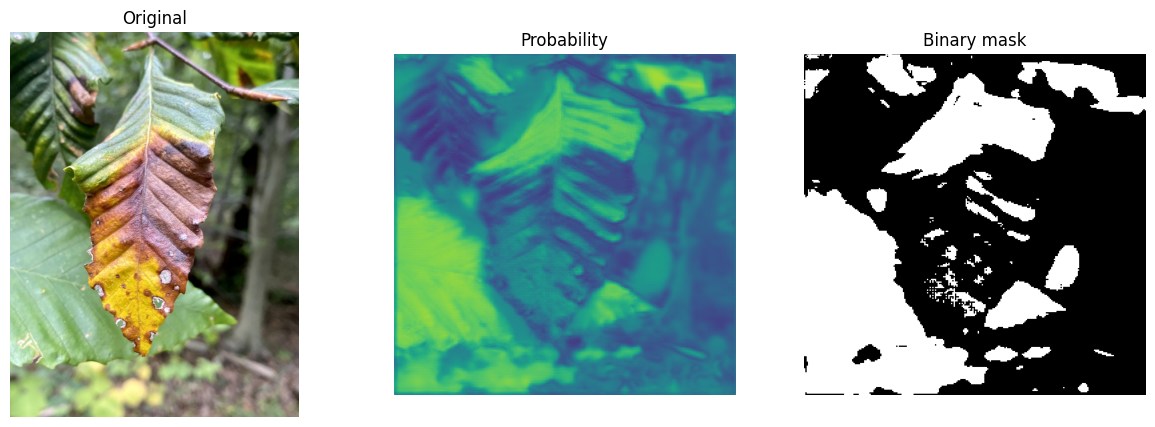

In [33]:
resized = image.resize(
    (IMAGE_SIZE[1], IMAGE_SIZE[0]),
    Image.Resampling.BILINEAR
)

image_array = (
    np.asarray(resized, dtype=np.float32) / 255.0
)

image_tensor = torch.from_numpy(
    image_array
).permute(2, 0, 1).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(image_tensor)
    probability = torch.sigmoid(logits)[0, 0].cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original")

axes[1].imshow(probability, cmap="viridis", vmin=0, vmax=1)
axes[1].set_title("Probability")

axes[2].imshow(probability > 0.5, cmap="gray")
axes[2].set_title("Binary mask")

for ax in axes:
    ax.axis("off")

plt.show()